# SBHCloud (10 levels, no cooling, n384)

In [3]:
using Plots, Printf, Measures
using LaTeXStrings
include("../../../Utils/misc_stdout.jl")

Main.MiscStdout

## Strong Scaling

In [ ]:
let patt_dirss = [
        #([
        #    (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool"),
        #], "../data/BBHCloud_8lvl_nocool/n256/strong/", :cross),
        ([
            (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool-bigbox"),
        ], "../data/BBHCloud_8lvl_nocool/n256/strong-bigbox/", :x),
    ]

    xs = [1, 2, 4, 8, 16]

    # Plot Zcs/sec (left y-axis)
    plt = plot(
        title=L"\mathrm{Strong\,\,Scaling}",
        ylabel=L"\mathrm{zone-cycles\,\,s^{-1}}\,\,[10^8]",
        xlabel=L"\mathrm{Frontier\,\,Nodes}",
        xscale=:log10, yscale=:log10,
        legend=:bottomright,
        foreground_color_legend=nothing,
        background_color_legend=:white,
        legendfontsize=10,
        grid=true,
        gridalpha=0.3,
        minorgrid=false,
        size=(500,500)
    )
    xticks!(plt, xs, [string(n) for n in xs])
    ys = [1e8, 1e9, 1e10]
    yticks!(plt, ys, [L"10^{0}", L"10^{1}", L"10^{2}"])

    println("Zcs/sec:")
    for (patterns, parent_dir, mark) in patt_dirss
        # Load averages for the given patterns and directory
        dats, labs = MiscStdout.load_avgs(patterns, parent_dir; option = "ZcsPerSecond", range=:)
        # Iterate through the loaded datasets
        for (i, dat) in enumerate(dats)
            # Plot Zcs/sec (actual)
            plot!(plt, dat[1], dat[2], label=L"\mathrm{256^3\,\,Points\,\,8\,\,lvl}",
                  marker=:utriangle, markersize=8, markerstrokewidth=0, color=:black, linewidth=1.5)
            # Plot Ideal scaling
            plot!(plt, dat[1], dat[2][1] .* dat[1], label=L"\mathrm{Ideal}",
                  linestyle=:dash, color=:gray, marker=:utriangle, markersize=8,
                  markerstrokewidth=0, linewidth=1.5)

            @printf("  %8s: [", labs[i])
            println(join([@sprintf(" %8.2e", d) for d in dat[2]], ","), "]")

            # Plot Efficiency (right y-axis)
            value_per_node = dat[2] ./ dat[1]
            efficiency = value_per_node ./ first(value_per_node)
            plt2 = twinx()
            ylims!(plt2, (0, 1.1))
            # Ideal efficiency line (dashed, light red)
            plot!(plt2, dat[1], ones(length(dat[1])), label="",
                  linestyle=:dash, color=RGBA(1.0, 0.4, 0.4, 0.7),
                  marker=:utriangle, markersize=8, markerstrokewidth=0, linewidth=1.5)
            # Actual efficiency (solid red)
            plot!(plt2, dat[1], efficiency, label="",
                  marker=:utriangle, markersize=8, markerstrokewidth=0, color=:red, linewidth=1.5,
                  ylabel=L"\mathrm{Efficiency}", xscale=:log10, xticks=:none,
                  yguidefontcolor=:red, ytickfontcolor=:red, yforeground_color_axis=:red)
        end
    end

    display(plt)
    #savefig(plt, "BBHCloud-8lvl-nocool-strong-scaling.pdf")
end

## Weak Scaling

Zcs/sec:
  SBHCloud-10lvl-nocool: [ 3.15e+08, 2.29e+09, 9.20e+09]
[1.0, 0.9094000957551637, 0.9135295724817335]


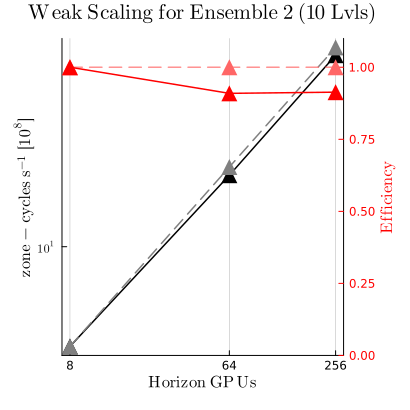

In [12]:
let patt_dirss = [
        #([
        #    (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool"),
        #], "../data/BBHCloud_8lvl_nocool/n256/weak/", :cross),
        ([
            (r"SBHCloud_8lvl_nocool_N\d+_r0000", "SBHCloud-10lvl-nocool"),
        ], "../data/SBHCloud_10lvl_nocool/n384/weak/", :x),
    ]

    gpus_per_node = 4  # Horizon runs N2, N16, and N64 report 8, 64, and 256 CUDA devices.

    # Plot Zcs/sec (left y-axis)
    plt = plot(
        title=L"\mathrm{Weak\,\,Scaling\,\,for\,\,Ensemble\,\,2\,\,(10\,\,Lvls)}",
        ylabel=L"\mathrm{zone-cycles\,\,s^{-1}}\,\,[10^8]",
        xlabel=L"\mathrm{Horizon\,\,GPUs}",
        xscale=:log10, yscale=:log10,
        legend=:bottomright,
        foreground_color_legend=nothing,
        background_color_legend=:white,
        legendfontsize=10,
        grid=true,
        gridalpha=0.3,
        minorgrid=false,
        size=(410,410)
    )
    ys = [1e8, 1e9]
    yticks!(plt, ys, [L"10^{0}", L"10^{1}"])

    println("Zcs/sec:")
    for (patterns, parent_dir, mark) in patt_dirss
        # Load averages for the given patterns and directory
        dats, labs = MiscStdout.load_avgs(patterns, parent_dir; option = "ZcsPerSecond", range=:)
        # Iterate through the loaded datasets
        for (i, dat) in enumerate(dats)
            nodes, throughput = dat
            gpus = gpus_per_node .* Int.(nodes)
            ideal_throughput = first(throughput) .* (gpus ./ first(gpus))
            xticks!(plt, gpus, string.(gpus))

            # Plot Zcs/sec (actual)
            plot!(plt, gpus, throughput, label="",
                  marker=:utriangle, markersize=8, markerstrokewidth=0, color=:black, linewidth=1.5)
            # Plot Ideal scaling
            plot!(plt, gpus, ideal_throughput, label="",
                  linestyle=:dash, color=:gray, marker=:utriangle, markersize=8,
                  markerstrokewidth=0, linewidth=1.5)

            @printf("  %8s: [", labs[i])
            println(join([@sprintf(" %8.2e", d) for d in throughput], ","), "]")

            # Plot Efficiency (right y-axis)
            efficiency = throughput ./ ideal_throughput
            plt2 = twinx()
            ylims!(plt2, (0, 1.1))
            # Ideal efficiency line (dashed, light red)
            plot!(plt2, gpus, ones(length(gpus)), label="",
                  linestyle=:dash, color=RGBA(1.0, 0.4, 0.4, 0.7),
                  marker=:utriangle, markersize=8, markerstrokewidth=0, linewidth=1.5)
            # Actual efficiency (solid red)
            plot!(plt2, gpus, efficiency, label="",
                  marker=:utriangle, markersize=8, markerstrokewidth=0, color=:red, linewidth=1.5,
                  ylabel=L"\mathrm{Efficiency}", xscale=:log10, xticks=:none,
                  yguidefontcolor=:red, ytickfontcolor=:red, yforeground_color_axis=:red)
            println(efficiency)
        end
    end

    display(plt)
    #savefig(plt, "SBHCloud-10lvl-nocool-weak-scaling.pdf")
end

## Speed

In [ ]:
let patt_dirss = [
        ([
            (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool-strong"),
        ], "../data/BBHCloud_8lvl_nocool/n256/strong/", :cross),
        ([
            (r"BBHCloud_8lvl_nocool_N\d+_r0000", "BBHCloud-8lvl-nocool-weak"),
        ], "../data/BBHCloud_8lvl_nocool/n256/weak/", :circle),
    ]

    plts = []
    for (patterns, parent_dir, mark) in patt_dirss
        (vals, titles) = MiscStdout.load_values(patterns, parent_dir; option="TotalComputeTime")
        for (j, val) in enumerate(vals)
            (dats, labs) = val
            plt = plot(title=titles[j])
            for (i, dat) in enumerate(dats)
                plot!(plt, dat[1], dat[4], label=labs[i], marker=mark)
            end
            push!(plts, plt)
        end
    end

    plt = plot(plts..., layout=(length(plts), 1), size=(600, 300 * length(plts)))
    display(plt)
end